# Actividad — Construir un pipeline de preprocesamiento
**Aprendizaje Supervisado · Unidad 2 · Preprocesamiento de datos**

**Qué haremos.** En la presentación vimos las piezas del preprocesamiento. Hoy las usarás sobre la versión original de
*California Housing* (con valores faltantes y una variable categórica) y, sobre todo, **medirás** el efecto de cada decisión:
¿qué imputación conviene? ¿importa cómo codifico? ¿qué pasa si escalo mal o si hay fuga de datos?

| Parte | Pregunta que responde | Tema de la presentación |
|---|---|---|
| 1 | ¿Cuántos datos faltan y se parecen las filas con y sin faltante? | A1–A3 |
| 2 | ¿Cómo divido sin distorsionar las proporciones? | D1–D3 |
| 3 | ¿Qué estrategia de imputación recupera mejor los valores ocultos? | A4–A9 |
| 4 | ¿Entero u *one-hot*? ¿Y si el orden sí importa? | B1–B5 |
| 5 | ¿Qué escalador conviene y para qué modelos? | C1–C6 |
| 6 | ¿Cómo se ve (y se evita) una fuga de datos? | D5–D7 |
| 7 | ¿Cómo empaqueto todo con `Pipeline` y `ColumnTransformer`? | E1–E5 |
| 8 | Tabla comparativa y resumen | Receta de siete pasos |

**Tiempo estimado:** 60–75 minutos de trabajo individual.

**Entregable:** este notebook ejecutado (con tus respuestas en las celdas ✏️) y el archivo `entregable_unidad2.csv`
con la tabla *estrategia · RMSE de validación · comentario* de la Parte 8.

**Cómo trabajar.** Ejecuta las celdas en orden. Donde dice ✏️ hay una línea de código por completar o una pregunta;
escribe tus respuestas en la celda de texto que sigue a la pregunta, bajo «**Respuesta:**».
Todas las cifras de error están en **miles de USD** (valor mediano de la vivienda ÷ 1000).

In [24]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.experimental import enable_iterative_imputer  # noqa: F401  (activa IterativeImputer)
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder, OrdinalEncoder
from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import mean_squared_error, r2_score

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 140)

## Parte 0 — Los datos

Usamos la versión del libro de A. Géron (*Hands-On Machine Learning*): $n=20\,640$ distritos de California, con
`total_bedrooms` incompleta y una variable categórica, `ocean_proximity`. El archivo se descarga de GitHub la primera vez
(se necesita conexión a internet).

In [25]:
URL = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
try:
    df = pd.read_csv(URL)
except Exception:
    df = pd.read_csv("housing.csv")      # plan B: si descargaste el archivo y lo dejaste junto al notebook

NUM = ["longitude", "latitude", "housing_median_age", "total_rooms",
       "total_bedrooms", "population", "households", "median_income"]
CAT = ["ocean_proximity"]
OBJ = "median_house_value"
cv = KFold(5, shuffle=True, random_state=0)      # validación cruzada de 5 particiones, siempre la misma

print(df.shape)
df.head()

(20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## Parte 1 — Cuantificar los valores faltantes  *(presentación A1–A3)*

Antes de imputar o borrar hay que saber **cuántos** faltan, **dónde**, y si las filas incompletas se parecen a las completas.

In [26]:
n_falt = df.isna().sum()      # ✏️ número de NaN por columna        (pista: df.isna().sum())
pct_falt = 100 * df.isna().mean()    # ✏️ porcentaje de filas con NaN       (pista: 100 * df.isna().mean())
tabla_falt = pd.DataFrame({"faltantes": n_falt, "%": pct_falt.round(2)})
print(tabla_falt[tabla_falt["faltantes"] > 0])
print("Filas completas:", len(df.dropna()), "de", len(df))

                faltantes    %
total_bedrooms        207  1.0
Filas completas: 20433 de 20640


In [27]:
# ¿Se parecen los distritos con y sin dato en total_bedrooms?
falta = df["total_bedrooms"].isna().map({True: "sin dato", False: "con dato"})
cols = ["median_income", "median_house_value", "housing_median_age", "population"]
df.groupby(falta)[cols].mean().round(2)

,median_income,median_house_value,housing_median_age,population
total_bedrooms,,,,
con dato,3.87,206864.41,28.63,1424.95
sin dato,3.82,206007.28,29.27,1477.77


In [28]:
# ¿Hay faltantes "disfrazados"? Revisa ceros y valores imposibles en las columnas numéricas
print((df[NUM] == 0).sum().to_string())
print()
print(df[NUM].describe().loc[["min", "max"]].T)

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0

                         min         max
longitude          -124.3500   -114.3100
latitude             32.5400     41.9500
housing_median_age    1.0000     52.0000
total_rooms           2.0000  39320.0000
total_bedrooms        1.0000   6445.0000
population            3.0000  35682.0000
households            1.0000   6082.0000
median_income         0.4999     15.0001


✏️ **Pregunta 1.1.** Con base en las dos tablas anteriores, ¿qué mecanismo (MCAR, MAR o MNAR) te parece más plausible para `total_bedrooms`?
¿Qué **no** puedes concluir solo con esta comparación? ¿Encontraste faltantes disfrazados?

**Respuesta:** Las filas sin dato son casi idénticas a las que sí lo tienen (ingreso 3.82 vs 3.87; valor 206 mil vs 207 mil; edad 29.3 vs 28.6; población 1478 vs 1425), y son solo 207 filas (1 %). Lo más plausible es **MCAR** (o, a lo sumo, un MAR muy débil). Lo que **no** puedo concluir: la comparación solo usa variables *observadas*; no descarta MNAR (que la ausencia dependa del propio número de dormitorios, que justamente no vemos), ni diferencias en otras columnas o en la forma de la distribución (solo comparé medias). Faltantes disfrazados como ceros: **no** hay (cero ceros y los mínimos son 1 o más). Sí hay valores topados que parecen censura: `median_income` máx. 15.0001 y `housing_median_age` máx. 52.

## Parte 2 — Dividir **primero**, de forma estratificada  *(presentación D1–D3)*

Regla de la receta: lo primero es separar el conjunto de prueba. Como el ingreso mediano es la variable que más
explica el precio, queremos que la **distribución del ingreso** sea la misma en entrenamiento y en prueba.
Creamos una variable auxiliar `income_cat` (5 categorías de ingreso) solo para **estratificar**.

In [29]:
df["income_cat"] = pd.cut(df["median_income"], bins=[0, 1.5, 3.0, 4.5, 6.0, np.inf], labels=[1, 2, 3, 4, 5])

train, test = train_test_split(df, test_size=0.2, random_state=42, stratify=df["income_cat"])

prop = pd.DataFrame({
    "total": df["income_cat"].value_counts(normalize=True),
    "entrenamiento": train["income_cat"].value_counts(normalize=True),
    "prueba": test["income_cat"].value_counts(normalize=True),
}).sort_index().mul(100).round(1)
print(prop)
print("\nTamaños:", len(train), "entrenamiento |", len(test), "prueba")

            total  entrenamiento  prueba
income_cat                              
1             4.0            4.0     4.0
2            31.9           31.9    31.9
3            35.1           35.1    35.1
4            17.6           17.6    17.6
5            11.4           11.4    11.4

Tamaños: 16512 entrenamiento | 4128 prueba


In [30]:
# Separamos atributos y objetivo (en miles de USD) y quitamos la variable auxiliar
X_train, y_train = train.drop(columns=[OBJ, "income_cat"]), train[OBJ] / 1000
X_test,  y_test  = test.drop(columns=[OBJ, "income_cat"]),  test[OBJ] / 1000
# A partir de aquí, el conjunto de prueba NO se toca hasta el final de la Parte 7/8.
X_train.shape, X_test.shape

((16512, 9), (4128, 9))

✏️ **Pregunta 2.1.** Compara las columnas *total*, *entrenamiento* y *prueba* de la tabla de proporciones.
¿Por qué estratificamos por el ingreso y no por, por ejemplo, `population`? ¿Qué podría pasar con una división aleatoria simple?

**Respuesta:** Con `stratify` las tres columnas coinciden prácticamente al 0.1 % (4.0 / 31.9 / 35.1 / 17.6 / 11.4 %). Se estratifica por el ingreso porque es el predictor que más explica el precio: si la prueba tuviera una mezcla de ingresos distinta de la real, la estimación del error quedaría sesgada. `population` no explica el precio de forma comparable, y además es continua con cola muy larga. Con una división aleatoria simple, por azar la muestra de prueba podría sub o sobrerrepresentar las categorías pequeñas (la 1 es solo 4 % y la 5 solo 11 %) y el error en prueba no sería comparable con el de entrenamiento.

## Parte 3 — ¿Qué imputación recupera mejor los valores? *(presentación A4–A9)*

Para comparar estrategias necesitamos conocer la **verdad**. Tomamos las filas de entrenamiento donde `total_bedrooms` sí
existe, **ocultamos el 20 %** al azar, imputamos y medimos el error contra el valor real.

In [31]:
base = X_train[NUM].dropna(subset=["total_bedrooms"]).reset_index(drop=True)
rng = np.random.default_rng(5)
oculto = rng.random(len(base)) < 0.20                       # True = valor que ocultamos
verdad = base.loc[oculto, "total_bedrooms"].values
X_mask = base.copy()
X_mask.loc[oculto, "total_bedrooms"] = np.nan
j = NUM.index("total_bedrooms")
print(f"Ocultamos {oculto.sum()} de {len(base)} valores")

imputaciones = {}
imputaciones["media"] = SimpleImputer(strategy="mean").fit_transform(X_mask)[oculto, j]  # ✏️ SimpleImputer(strategy=...).fit_transform(X_mask)[oculto, j]
imputaciones["mediana"] = SimpleImputer(strategy="median").fit_transform(X_mask)[oculto, j]  # ✏️ igual, con la mediana

# KNN usa distancias: lo probamos sin escalar y con las variables estandarizadas
imputaciones["KNN (sin escalar)"] = KNNImputer(n_neighbors=5).fit_transform(X_mask)[oculto, j]
esc = StandardScaler().fit(X_mask)
X_knn = KNNImputer(n_neighbors=5).fit_transform(esc.transform(X_mask))
imputaciones["KNN (escalado)"] = esc.inverse_transform(X_knn)[oculto, j]
# Imputación iterativa (tipo MICE)
imputaciones["Iterativa (MICE)"] = IterativeImputer(max_iter=10, random_state=0).fit_transform(X_mask)[oculto, j]

Ocultamos 3313 de 16354 valores


                         RMSE  desv. est.  corr. con households
método                                                         
verdad (sin ocultar)    0.000     412.666                 0.980
media                 397.445     371.883                 0.883
mediana               407.344     374.154                 0.879
KNN (sin escalar)      74.269     409.478                 0.980
KNN (escalado)         64.317     408.732                 0.980
Iterativa (MICE)       67.284     411.746                 0.982


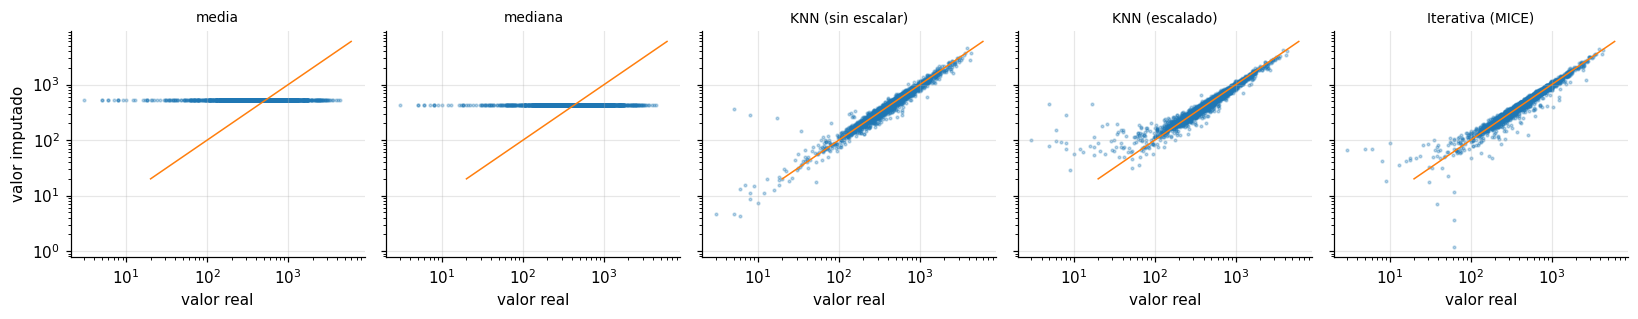

In [32]:
filas = [{"método": "verdad (sin ocultar)", "RMSE": 0.0,
          "desv. est.": base["total_bedrooms"].std(), "corr. con households": base["total_bedrooms"].corr(base["households"])}]
for nombre, vals in imputaciones.items():
    col = base["total_bedrooms"].copy()
    col[oculto] = vals                                      # columna completa tras imputar
    filas.append({"método": nombre,
                  "RMSE": float(np.sqrt(np.mean((vals - verdad) ** 2))),
                  "desv. est.": col.std(),
                  "corr. con households": col.corr(base["households"])})
tabla_imp = pd.DataFrame(filas).set_index("método").round(3)
print(tabla_imp)

fig, ax = plt.subplots(1, 5, figsize=(15, 3), sharex=True, sharey=True)
for a, (nombre, vals) in zip(ax, imputaciones.items()):
    a.scatter(verdad, vals, s=3, alpha=0.3)
    a.plot([20, 6000], [20, 6000], color="C1", lw=1)
    a.set_xscale("log"); a.set_yscale("log"); a.set_title(nombre, fontsize=9); a.set_xlabel("valor real")
ax[0].set_ylabel("valor imputado")
plt.tight_layout(); plt.show()

✏️ **Pregunta 3.1.** (a) Para media y mediana, ¿por qué el RMSE es tan parecido a la desviación estándar de la variable
y qué se ve en las gráficas? (b) ¿Qué le pasa a la desviación estándar y a la correlación con `households` al imputar con la media?
(c) ¿Qué cambia entre *KNN sin escalar* y *KNN escalado*, y por qué?

**Respuesta:** (a) La media y la mediana asignan **el mismo número** a todos los faltantes sin mirar ninguna otra columna; el error de predecir una constante es, por construcción, del orden de la dispersión de la variable (RMSE ≈ 397-407 frente a una desviación de ≈ 412). En las gráficas se ve una **línea horizontal**: todo valor real, chico o grande, recibe el mismo imputado. (b) Al imputar con la media la desviación estándar baja (de 412.7 a 371.9) y la correlación con `households` cae de 0.980 a 0.883: se comprimen la varianza y las relaciones entre variables, que es justo lo que un modelo aprovecharía. KNN y MICE las conservan (≈ 409-412 y 0.98). (c) Sin escalar el RMSE es 74.3 y escalado 64.3. KNN usa distancias; sin escalar dominan las variables de magnitud grande (`total_rooms`, `population`) y las de escala pequeña (ingreso, latitud, longitud) prácticamente no cuentan al escoger vecinos. Al estandarizar todas pesan parecido y los vecinos son más parecidos de verdad.

✏️ **Pregunta 3.2.** Una tienda de crédito guarda `ingreso` solo para quienes lo declaran, y los que más ganan casi nunca lo declaran.
¿Qué mecanismo es? ¿Resolvería el problema una imputación con KNN? ¿Qué agregarías al modelo?

**Respuesta:** Es **MNAR**: la probabilidad de faltar depende del propio valor no observado (quien más gana, menos declara). KNN **no** lo resuelve: imputa a partir de vecinos que sí declararon, que ganan menos en promedio, así que subestima sistemáticamente el ingreso de los faltantes. Lo que agregaría: un **indicador de faltante** (`add_indicator=True`), porque el hecho de no declarar ya es informativo; más variables del dominio que se relacionen con el ingreso (empleo, gasto), un análisis de sensibilidad con distintos supuestos sobre el mecanismo y, si es posible, obtener el dato por otra fuente.

## Parte 4 — Codificar `ocean_proximity` *(presentación B1–B5)*

Comparamos dos formas de convertir la categoría en números, ajustando los codificadores **solo con el entrenamiento**
y usando una regresión lineal con esa única variable.

In [33]:
print(X_train["ocean_proximity"].value_counts().to_string())
print("\nEn prueba:\n" + X_test["ocean_proximity"].value_counts().to_string())

ocean_proximity
<1H OCEAN     7277
INLAND        5262
NEAR OCEAN    2124
NEAR BAY      1847
ISLAND           2

En prueba:
ocean_proximity
<1H OCEAN     1859
INLAND        1289
NEAR OCEAN     534
NEAR BAY       443
ISLAND           3


In [34]:
cat_train, cat_test = X_train[CAT], X_test[CAT]

ord_enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1).fit(cat_train)  # ✏️ OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1).fit(cat_train)
oh_enc = OneHotEncoder(handle_unknown="ignore").fit(cat_train)  # ✏️ OneHotEncoder(handle_unknown="ignore").fit(cat_train)

print("Códigos enteros:", dict(zip(ord_enc.categories_[0], range(len(ord_enc.categories_[0])))))
print("Columnas one-hot:", list(oh_enc.get_feature_names_out()))

for nombre, enc in [("entero", ord_enc), ("one-hot", oh_enc)]:
    A_tr, A_te = enc.transform(cat_train), enc.transform(cat_test)
    lr = LinearRegression().fit(A_tr, y_train)
    print(f"{nombre:8s} R² entrenamiento = {lr.score(A_tr, y_train):.3f}   R² prueba = {lr.score(A_te, y_test):.3f}")

Códigos enteros: {'<1H OCEAN': 0, 'INLAND': 1, 'ISLAND': 2, 'NEAR BAY': 3, 'NEAR OCEAN': 4}
Columnas one-hot: ['ocean_proximity_<1H OCEAN', 'ocean_proximity_INLAND', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN']
entero   R² entrenamiento = 0.006   R² prueba = 0.010
one-hot  R² entrenamiento = 0.236   R² prueba = 0.248


In [35]:
# Cuando el orden SÍ existe: tallas S < M < L
tallas = pd.DataFrame({"talla": ["M", "S", "L", "M", "S"]})
enc = OrdinalEncoder(categories=[["S", "M", "L"]])          # ✏️ mira los códigos que asigna; corrígelo con categories=[["S", "M", "L"]]
tallas["código"] = enc.fit_transform(tallas[["talla"]])
tallas

,talla,código
0,M,1.0
1,S,0.0
2,L,2.0
3,M,1.0
4,S,0.0


✏️ **Pregunta 4.1.** (a) ¿Por qué el código entero ajusta tan mal y el *one-hot* mucho mejor? (b) ¿Qué ocurriría si
`ISLAND` aparece en prueba pero no en entrenamiento, y qué hace `handle_unknown="ignore"`? (c) ¿Qué códigos asignó `OrdinalEncoder` por defecto a las tallas y por qué eso es un error?

**Respuesta:** (a) Los códigos enteros imponen un orden y espaciado inexistentes (`<1H OCEAN`=0, `INLAND`=1, `ISLAND`=2, ... por orden alfabético), y la regresión lineal solo puede ajustar **una pendiente** sobre ese número: R² ≈ 0.006. Con one-hot cada categoría tiene su propio nivel (su propio promedio): R² ≈ 0.24 en entrenamiento y 0.25 en prueba. (b) `ISLAND` casi no existe (2 filas en entrenamiento y 3 en prueba); con otra partición podría aparecer solo en prueba. Sin `handle_unknown` el `transform` lanzaría un error por categoría no vista; con `"ignore"` esa fila recibe ceros en todas las columnas one-hot (nunca falla, pero no sabe nada de la categoría nueva). (c) Por defecto asigna por orden alfabético: `L`=0, `M`=1, `S`=2, es decir, **invierte** el orden real S < M < L. Se corrige con `categories=[["S", "M", "L"]]` (S=0, M=1, L=2).

## Parte 5 — Escalar: ¿cuál y para qué modelo? *(presentación C1–C6)*

Primero verifica la regla **fit con entrenamiento, transform con todos**; después compara cuatro opciones de escalado con dos modelos.

In [36]:
imp = SimpleImputer(strategy="median").fit(X_train[NUM])
Xtr, Xte = imp.transform(X_train[NUM]), imp.transform(X_test[NUM])

sc = StandardScaler().fit(Xtr)                      # ✏️ StandardScaler ajustado (fit) con Xtr
Ztr, Zte = sc.transform(Xtr), sc.transform(Xte)

print(pd.DataFrame({"media entren.": Ztr.mean(0), "desv. entren.": Ztr.std(0),
                    "media prueba": Zte.mean(0), "desv. prueba": Zte.std(0)}, index=NUM).round(3))

                    media entren.  desv. entren.  media prueba  desv. prueba
longitude                    -0.0            1.0         0.015         1.004
latitude                      0.0            1.0        -0.017         0.995
housing_median_age            0.0            1.0        -0.006         1.004
total_rooms                  -0.0            1.0         0.031         1.097
total_bedrooms               -0.0            1.0         0.035         1.100
population                    0.0            1.0         0.026         1.073
households                   -0.0            1.0         0.034         1.085
median_income                 0.0            1.0        -0.014         0.986


In [37]:
def cv_rmse(modelo, Xd, yd):
    s = -cross_val_score(modelo, Xd, yd, cv=cv, scoring="neg_root_mean_squared_error")
    return s.mean(), s.std()

escaladores = {"sin escalar": "passthrough", "StandardScaler": StandardScaler(),
               "MinMaxScaler": MinMaxScaler(), "RobustScaler": RobustScaler()}
modelos = {"KNN (k=10)": KNeighborsRegressor(n_neighbors=10),
           "Árbol (prof. 8)": DecisionTreeRegressor(max_depth=8, random_state=0)}

filas = []
for nom_esc, escalador in escaladores.items():
    for nom_mod, modelo in modelos.items():
        pipe = Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", escalador), ("modelo", modelo)])  # ✏️ Pipeline con tres pasos: imputador (mediana), escalador y modelo
        m, s = cv_rmse(pipe, X_train[NUM], y_train)
        filas.append({"escalador": nom_esc, "modelo": nom_mod, "RMSE validación": round(m, 2), "± desv": round(s, 2)})

tabla_esc = pd.DataFrame(filas).pivot(index="escalador", columns="modelo", values="RMSE validación")
tabla_esc.loc[list(escaladores)]

modelo,KNN (k=10),Árbol (prof. 8)
escalador,,
sin escalar,96.63,66.87
StandardScaler,62.59,66.89
MinMaxScaler,63.44,66.84
RobustScaler,64.02,66.89


✏️ **Pregunta 5.1.** (a) En la primera tabla, ¿las medias y desviaciones de **prueba** son exactamente 0 y 1? ¿Por qué no, y por qué eso es correcto?
(b) En la segunda tabla, ¿qué modelo se beneficia de escalar y cuál no? (c) ¿Diferencias entre los tres escaladores en este conjunto? ¿Cuándo preferirías `RobustScaler`?

**Respuesta:** (a) No: en prueba la media va de -0.017 a 0.035 y la desviación de 0.99 a 1.10, mientras que en entrenamiento son exactamente 0 y 1. Es correcto porque el escalador se ajustó **solo con entrenamiento** y se aplicó igual a prueba; la prueba es una muestra distinta, así que no tiene por qué quedar centrada. Forzarla a 0 y 1 significaría usar información de prueba (fuga) y en producción no tendríamos esos datos. (b) **KNN** se beneficia muchísimo (96.6 sin escalar vs 62.6 estandarizado); el **árbol** no (≈ 66.9 en todos los casos), porque sus cortes son invariantes a transformaciones monótonas de cada variable. (c) Entre los tres escaladores la diferencia es pequeña (62.6, 63.4 y 64.0). Prefiero `RobustScaler` cuando hay valores atípicos fuertes (aquí, `total_rooms` llega a 39 320) que inflarían la desviación o el rango y comprimirían al resto, y no quiero eliminarlos.

## Parte 6 — Provocar y medir una fuga de datos *(presentación D5–D7)*

Datos de **puro ruido**: 100 filas, 2 000 atributos al azar y una etiqueta 0/1 al azar. No hay nada que aprender, así que
la exactitud correcta es ≈ 0.50. Repetimos 10 veces dos procedimientos:

* **Con fuga:** elegir los 20 atributos «más relacionados» con la etiqueta usando *todos* los datos, y *después* validar.
* **Sin fuga:** hacer esa selección *dentro* de cada partición, con un `Pipeline`.

Con fuga:  exactitud media = 0.85
Sin fuga:  exactitud media = 0.52   (azar = 0.50)


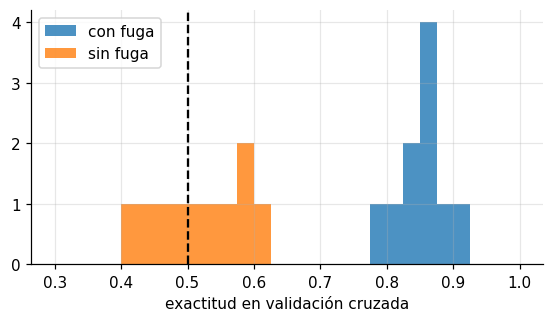

In [38]:
rng = np.random.default_rng(0)
con_fuga, sin_fuga = [], []
for rep in range(10):
    Xr = rng.normal(size=(100, 2000))
    yr = rng.integers(0, 2, 100)

    # CON FUGA: la selección ya "vio" todas las etiquetas
    Xsel = SelectKBest(f_classif, k=20).fit_transform(Xr, yr)
    con_fuga.append(cross_val_score(LogisticRegression(max_iter=500), Xsel, yr, cv=5).mean())

    pipe_ok = Pipeline([("sel", SelectKBest(f_classif, k=20)), ("lr", LogisticRegression(max_iter=500))])  # ✏️ Pipeline: selección SelectKBest(f_classif, k=20) y luego LogisticRegression
    sin_fuga.append(cross_val_score(pipe_ok, Xr, yr, cv=5).mean())

print(f"Con fuga:  exactitud media = {np.mean(con_fuga):.2f}")
print(f"Sin fuga:  exactitud media = {np.mean(sin_fuga):.2f}   (azar = 0.50)")
plt.figure(figsize=(6, 3))
plt.hist(con_fuga, bins=np.linspace(0.3, 1, 29), alpha=0.8, label="con fuga")
plt.hist(sin_fuga, bins=np.linspace(0.3, 1, 29), alpha=0.8, label="sin fuga")
plt.axvline(0.5, color="k", ls="--"); plt.xlabel("exactitud en validación cruzada"); plt.legend(); plt.show()

✏️ **Pregunta 6.1.** (a) ¿Por qué el procedimiento con fuga «encuentra» un patrón que no existe? (b) En la Parte 5, escalar antes de dividir
sí es una fuga, pero casi no cambiaría los resultados; aquí la selección sí los cambia enormemente. ¿Por qué la diferencia?
(c) Nombra otra fuga posible en un problema de crédito (pista: la tabla D5 de la presentación).

**Respuesta:** (a) Con 2 000 atributos y 100 filas, algunos atributos de ruido se correlacionan con la etiqueta *por azar*. Elegir los 20 «mejores» con todas las etiquetas selecciona precisamente esos, y la validación cruzada después los evalúa con filas cuyas etiquetas ya se usaron para elegirlos: 0.85 de exactitud donde no hay nada que aprender (la diapositiva D6 reporta 0.84 con fuga y 0.51 sin ella, con 40 repeticiones). (b) El escalador solo usa estadísticos de X (media y desviación, dos números por columna estimados con muchas filas): casi no transporta información. La selección usa las etiquetas y escoge 20 entre 2 000 candidatos con pocas filas, de modo que absorbe mucho azar (comparaciones múltiples). (c) Según la tabla D5: **fuga del objetivo**, por ejemplo usar «días de atraso» para predecir si habrá mora (dato que no se tendría al predecir); **duplicados**, la misma persona en entrenamiento y prueba (se evita eliminando duplicados o dividiendo por grupos); y **fuga temporal**, mezclar el futuro con el pasado, por ejemplo al validar con una división aleatoria el historial de pagos de un cliente (se evita con división temporal).

## Parte 7 — El pipeline completo *(presentación E1–E5)*

Empaquetamos imputación, escalado y codificación en un solo objeto. Después lo validamos con validación cruzada
y buscamos hiperparámetros del modelo **y** del preprocesamiento.

> Tus cifras serán parecidas, no idénticas, a las del código de la diapositiva E4: allí la división de datos no estaba estratificada.

In [39]:
num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])  # ✏️ Pipeline: SimpleImputer (mediana) → StandardScaler
cat_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))])  # ✏️ Pipeline: SimpleImputer (most_frequent) → OneHotEncoder(handle_unknown="ignore")
prep = ColumnTransformer([("num", num_pipe, NUM), ("cat", cat_pipe, CAT)])  # ✏️ ColumnTransformer con ("num", num_pipe, NUM) y ("cat", cat_pipe, CAT)

modelo = Pipeline([("prep", prep), ("knn", KNeighborsRegressor(n_neighbors=10))])

# ¿Cuántas columnas produce el preprocesador? (debería ser 13: 8 numéricas + 5 one-hot)
print("Columnas tras preprocesar:", modelo[:-1].fit(X_train, y_train).transform(X_train).shape[1])
print(list(prep.get_feature_names_out()))

m, s = cv_rmse(modelo, X_train, y_train)
print(f"\nRMSE de validación cruzada: {m:.2f} ± {s:.2f}  (miles de USD)")

Columnas tras preprocesar: 13
['num__longitude', 'num__latitude', 'num__housing_median_age', 'num__total_rooms', 'num__total_bedrooms', 'num__population', 'num__households', 'num__median_income', 'cat__ocean_proximity_<1H OCEAN', 'cat__ocean_proximity_INLAND', 'cat__ocean_proximity_ISLAND', 'cat__ocean_proximity_NEAR BAY', 'cat__ocean_proximity_NEAR OCEAN']

RMSE de validación cruzada: 61.20 ± 0.86  (miles de USD)


In [40]:
param_grid = {
    "knn__n_neighbors": [5, 10, 20],
    "prep__num__imputer__strategy": ["mean", "median"],
}
busqueda = GridSearchCV(modelo, param_grid, cv=cv, scoring="neg_root_mean_squared_error")
busqueda.fit(X_train, y_train)

print("Mejores parámetros:", busqueda.best_params_)
print(f"RMSE de validación (mejor combinación): {-busqueda.best_score_:.2f}")
pd.DataFrame(busqueda.cv_results_)[["params", "mean_test_score"]].assign(RMSE=lambda d: -d["mean_test_score"]).drop(columns="mean_test_score").round(2)

Mejores parámetros: {'knn__n_neighbors': 10, 'prep__num__imputer__strategy': 'median'}
RMSE de validación (mejor combinación): 61.20


,params,RMSE
0,"{'knn__n_neighbors': 5, 'prep__num__imputer__s...",62.00
1,"{'knn__n_neighbors': 5, 'prep__num__imputer__s...",61.98
2,"{'knn__n_neighbors': 10, 'prep__num__imputer__...",61.20
3,"{'knn__n_neighbors': 10, 'prep__num__imputer__...",61.20
4,"{'knn__n_neighbors': 20, 'prep__num__imputer__...",61.52
5,"{'knn__n_neighbors': 20, 'prep__num__imputer__...",61.52


In [41]:
# Ahora sí: el conjunto de prueba se usa UNA sola vez, con el mejor modelo ya elegido
final = busqueda.best_estimator_
pred = final.predict(X_test)
rmse_prueba = float(np.sqrt(mean_squared_error(y_test, pred)))
print(f"RMSE en prueba: {rmse_prueba:.2f}   R² en prueba: {r2_score(y_test, pred):.3f}")

RMSE en prueba: 58.88   R² en prueba: 0.734


✏️ **Pregunta 7.1.** (a) ¿Qué significa el nombre `prep__num__imputer__strategy`? (b) ¿Por qué la búsqueda con `GridSearchCV` sobre un `Pipeline` **no** tiene fuga?
(c) Si en vez del pipeline hubieras hecho `StandardScaler().fit_transform(X)` sobre todo el conjunto y luego `GridSearchCV`, ¿qué habría salido mal?

**Respuesta:** (a) Es la ruta a un parámetro dentro del pipeline, separada por doble guion bajo: en el paso `prep` (el `ColumnTransformer`), subpipeline `num`, paso `imputer`, parámetro `strategy` (mean o median). (b) `GridSearchCV` clona y reajusta **todo** el pipeline en cada partición con solo la parte de entrenamiento de esa partición; la parte de validación solo se transforma con lo aprendido. Así imputador, escalador y codificador nunca ven los datos con los que se evalúan. (c) Los estadísticos del escalador se habrían calculado con todas las filas, incluidas las de validación de cada partición, de modo que la validación ya no sería datos nuevos y el error saldría optimista. Con un escalador el sesgo sería pequeño, pero con pasos que usan la etiqueta (selección de variables) sería grave, como en la Parte 6.

## Parte 8 — Tabla comparativa y resumen *(entregable)*

Compara estrategias completas de preprocesamiento con el **mismo modelo** (KNN, $k=10$) y la **misma validación cruzada**
sobre el conjunto de entrenamiento. Es el experimento de la segunda diapositiva de la presentación, ahora con tu propio código.

In [42]:
resultados, pipes = [], {}

def evalua(nombre, pipe, Xd=None, yd=None):
    Xd = X_train if Xd is None else Xd
    yd = y_train if yd is None else yd
    m, s = cv_rmse(pipe, Xd, yd)
    resultados.append({"estrategia": nombre, "RMSE validación": round(m, 2), "± desv": round(s, 2), "comentario": ""})
    pipes[nombre] = pipe
    print(f"{nombre:55s} {m:6.2f} ± {s:4.2f}")

def crea_prep(imp_num, esc):
    # preprocesador completo: numéricas (imputar + escalar) y categórica (moda + one-hot)
    return ColumnTransformer([
        ("num", make_pipeline(imp_num, esc), NUM),
        ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")), CAT)])

knn = lambda: KNeighborsRegressor(n_neighbors=10)
completas = X_train.dropna().index

evalua("1. Borrar filas incompletas, sin escalar", Pipeline([("knn", knn())]), X_train.loc[completas, NUM], y_train.loc[completas])
evalua("2. Imputar con mediana, sin escalar", make_pipeline(SimpleImputer(strategy="median"), knn()), X_train[NUM])
evalua("3. + estandarizar", make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), knn()), X_train[NUM])
evalua("4. + one-hot de ocean_proximity",
       Pipeline([("prep", crea_prep(SimpleImputer(strategy="median"), StandardScaler())), ("knn", knn())]))
# ✏️ Completa las estrategias 5, 6 y 7 (cambia solo el argumento de crea_prep):
evalua("5. Como 4, pero con RobustScaler",
       Pipeline([("prep", crea_prep(SimpleImputer(strategy="median"), RobustScaler())), ("knn", knn())]))
evalua("6. Como 4, pero imputando con KNNImputer",
       Pipeline([("prep", crea_prep(KNNImputer(n_neighbors=5), StandardScaler())), ("knn", knn())]))
evalua("7. Como 4, con indicador de faltante",
       Pipeline([("prep", crea_prep(SimpleImputer(strategy="median", add_indicator=True), StandardScaler())), ("knn", knn())]))

1. Borrar filas incompletas, sin escalar                 96.78 ± 0.91
2. Imputar con mediana, sin escalar                      96.63 ± 0.42
3. + estandarizar                                        62.59 ± 1.44
4. + one-hot de ocean_proximity                          61.20 ± 0.86
5. Como 4, pero con RobustScaler                         61.29 ± 1.02
6. Como 4, pero imputando con KNNImputer                 61.14 ± 0.84
7. Como 4, con indicador de faltante                     61.40 ± 0.94


In [43]:
tabla_final = pd.DataFrame(resultados)
comentarios = [
    "Perder el 1 % de filas casi no cambia nada, pero sin escalar KNN rinde muy mal (≈ 97).",
    "Imputar con mediana equivale a borrar en error: solo falta el 1 %. Conserva todas las filas y es más estable (± 0.42).",
    "Estandarizar es el cambio con mayor efecto: el error baja unos 34 mil porque KNN deja de depender de la magnitud.",
    "Agregar one-hot de ocean_proximity baja otro ~1.4: la ubicación respecto al mar aporta información.",
    "RobustScaler da lo mismo que StandardScaler (diferencia dentro del ruido): los atípicos no pesan mucho aquí.",
    "KNNImputer es la mejor por muy poco (diferencia menor que la desviación): no compensa mucho con solo 1 % faltante.",
    "El indicador de faltante no ayuda (ligeramente peor): con MCAR la ausencia no contiene señal.",
]
tabla_final["comentario"] = comentarios
tabla_final

,estrategia,RMSE validación,± desv,comentario
0,"1. Borrar filas incompletas, sin escalar",96.78,0.91,"Perder el 1 % de filas casi no cambia nada, pe..."
1,"2. Imputar con mediana, sin escalar",96.63,0.42,Imputar con mediana equivale a borrar en error...
2,3. + estandarizar,62.59,1.44,Estandarizar es el cambio con mayor efecto: el...
3,4. + one-hot de ocean_proximity,61.20,0.86,Agregar one-hot de ocean_proximity baja otro ~...
4,"5. Como 4, pero con RobustScaler",61.29,1.02,RobustScaler da lo mismo que StandardScaler (d...
5,"6. Como 4, pero imputando con KNNImputer",61.14,0.84,KNNImputer es la mejor por muy poco (diferenci...
6,"7. Como 4, con indicador de faltante",61.40,0.94,El indicador de faltante no ayuda (ligeramente...


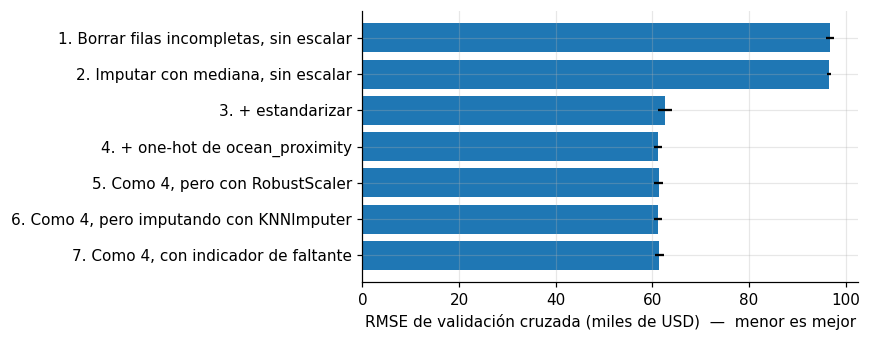

Guardado: entregable_unidad2.csv


In [44]:
plt.figure(figsize=(8, 3.2))
plt.barh(tabla_final["estrategia"][::-1], tabla_final["RMSE validación"][::-1], xerr=tabla_final["± desv"][::-1], color="C0")
plt.xlabel("RMSE de validación cruzada (miles de USD)  —  menor es mejor"); plt.tight_layout(); plt.show()

# Guarda la tabla para entregarla junto con el notebook
tabla_final.to_csv("entregable_unidad2.csv", index=False, encoding="utf-8")
print("Guardado: entregable_unidad2.csv")

In [45]:
# Mejor estrategia por validación → ajuste con TODO el entrenamiento → UNA evaluación en prueba
mejor = "6. Como 4, pero imputando con KNNImputer"        # ✏️ nombre de la estrategia 4–7 con menor RMSE de validación (cópialo de la tabla)
pipe_mejor = pipes[mejor]
pipe_mejor.fit(X_train, y_train)
pred = pipe_mejor.predict(X_test)
print(mejor)
print(f"RMSE en prueba: {np.sqrt(mean_squared_error(y_test, pred)):.2f}   R² en prueba: {r2_score(y_test, pred):.3f}")

6. Como 4, pero imputando con KNNImputer
RMSE en prueba: 58.85   R² en prueba: 0.734


### Reflexión final (3–5 líneas)

1. De todas las decisiones de preprocesamiento que probaste, ¿cuál cambió **más** el error y cuál casi nada? Relaciónalo con lo que pasa con los datos (escala, faltantes, categoría).
2. ¿Qué parte de este flujo habría tenido fuga si no hubieras usado `Pipeline`? ¿Y si hubieras escogido hiperparámetros mirando el conjunto de prueba?
3. Escribe tu **receta personal** (3 pasos) para empezar cualquier problema con datos tabulares nuevos.

**Respuesta:** 
1. **Lo que más cambió el error fue estandarizar para KNN** (de ≈ 96.6 a 62.6, unos 34 mil USD), porque las variables tenían escalas muy distintas y las distancias estaban dominadas por `total_rooms` y `population`. Le siguió el one-hot de `ocean_proximity` (≈ -1.4). **Casi nada** cambiaron borrar vs imputar (solo falta el 1 % y es casi MCAR), el tipo de escalador, el imputador (mediana vs KNN) ni el indicador de faltante; las diferencias son menores que la desviación entre particiones.
2. Sin `Pipeline`, imputar y escalar con todo el conjunto antes de la validación cruzada daría fuga (pequeña para estos pasos, grave para los que usan la etiqueta, como la selección de la Parte 6). Escoger hiperparámetros o estrategias mirando la prueba la dejaría de ser una estimación honesta: el error reportado sería optimista porque la prueba habría participado en la decisión.
3. **Receta:** (i) separar primero la prueba (estratificada si hace falta) y revisar faltantes y tipos de variable; (ii) armar un `Pipeline`/`ColumnTransformer` que impute, codifique y escale según el modelo, y comparar alternativas con validación cruzada; (iii) elegir con validación, reajustar con todo el entrenamiento y usar la prueba **una sola vez**.


---
### Reto opcional

Reemplaza `KNeighborsRegressor` por `DecisionTreeRegressor(max_depth=8)` en la estrategia 4 y compara contra las estrategias 2 y 3 (¿le importa el escalado?);
luego prueba `OneHotEncoder(handle_unknown="ignore", min_frequency=100)` y explica qué hace con `ISLAND`.

In [46]:
# Reto opcional
arbol = lambda: DecisionTreeRegressor(max_depth=8, random_state=0)
for nombre, pipe, Xd in [
    ("árbol, mediana, sin escalar", make_pipeline(SimpleImputer(strategy="median"), arbol()), X_train[NUM]),
    ("árbol, mediana + estandarizar", make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), arbol()), X_train[NUM]),
    ("árbol, preprocesador completo", Pipeline([("prep", crea_prep(SimpleImputer(strategy="median"), StandardScaler())), ("arbol", arbol())]), X_train),
]:
    m, s = cv_rmse(pipe, Xd, y_train)
    print(f"{nombre:34s} {m:6.2f} ± {s:4.2f}")

oh_raros = OneHotEncoder(handle_unknown="ignore", min_frequency=100).fit(X_train[CAT])
print("\nCategorías tras min_frequency=100:", list(oh_raros.get_feature_names_out()))

árbol, mediana, sin escalar         66.87 ± 2.30
árbol, mediana + estandarizar       66.89 ± 2.26
árbol, preprocesador completo       64.02 ± 1.61

Categorías tras min_frequency=100: ['ocean_proximity_<1H OCEAN', 'ocean_proximity_INLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN', 'ocean_proximity_infrequent_sklearn']


**Respuesta al reto.** El árbol no se beneficia del escalado (66.86 sin escalar vs 66.87 estandarizado), pero sí del one-hot de `ocean_proximity` (64.01). Con `min_frequency=100`, `ISLAND` (solo 2 filas en entrenamiento) pasa a la categoría agrupada `ocean_proximity_infrequent_sklearn` (las categorías con menos de 100 filas se juntan ahí), así que no se crea una columna casi vacía.